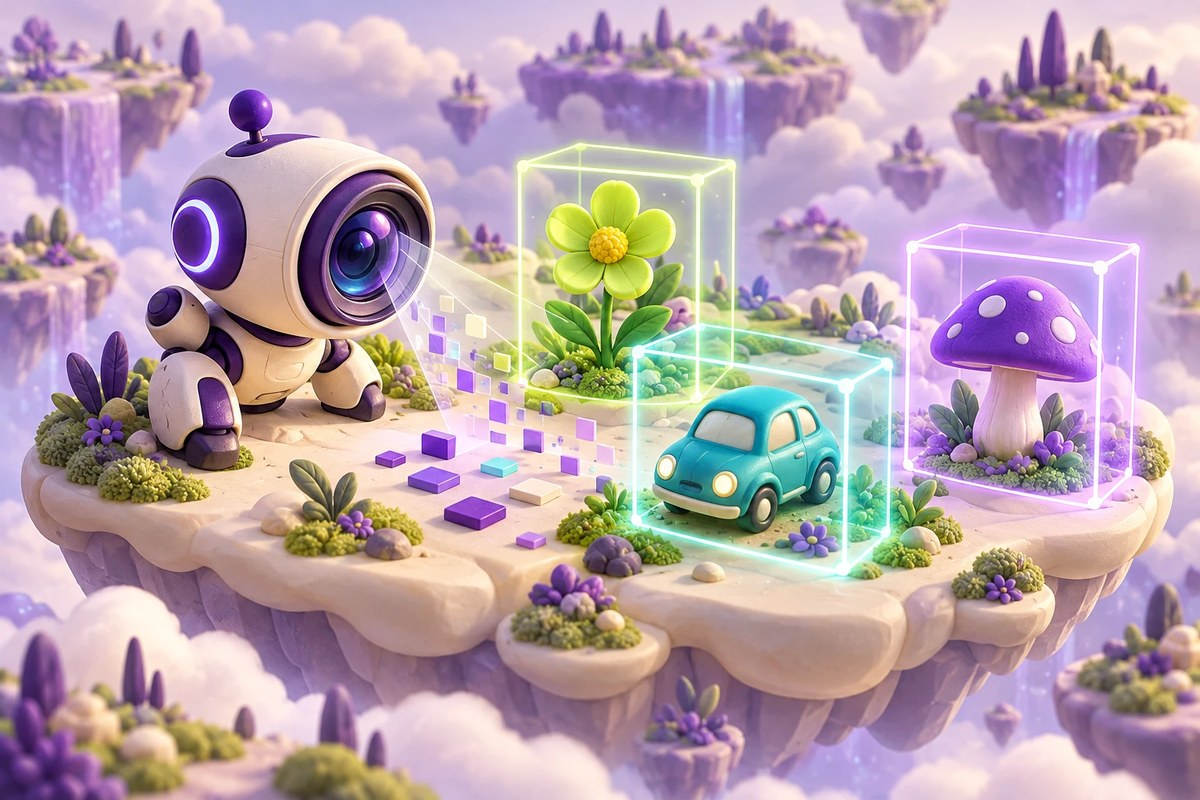

AI PATH · Компьютерное зрение · Урок 053

# ResNet152: признаки и дообучение

Учебный разбор глубокой остаточной сети на архивном наборе

**Архивный учебный материал.** Код и сохранённые результаты относятся к исходному ноутбуку. Оформление не означает новый запуск или подтверждение старых метрик. Перед выполнением проверьте зависимости и ограничения.

<a id="ai-053-goal"></a>
## Что вы разберёте

Проследить два этапа переноса обучения ResNet152 и проверить, какие слои и данные фактически участвуют в каждом этапе.

### Перед началом

- Тензоры изображений и бинарная классификация
- Перенос обучения и замороженные слои
- Разделение обучения, валидации и независимой проверки

### Что понадобится

- Учебный архив tuberculosis.zip по внешней ссылке исходника; каталоги base_dir/train_dir и base_dir/val_dir
- TensorFlow/Keras с моделью ResNet152, ImageDataGenerator, NumPy и Matplotlib
- Веса ImageNet; изображения приводятся к 299 × 299, batch_size=32
- Совместимая среда для wget/unzip и вычислительный ресурс, соответствующий выбранной архитектуре

## Навигация по уроку

- [Цель и подготовка](#ai-053-goal)
- [Карта урока](#ai-053-map)
- [Архитектура и учебный контекст](#ai-053-section-01)
- [Источник и разметка](#ai-053-section-02)
- [Аугментации и входная шкала](#ai-053-section-03)
- [Остаточная основа и новая голова](#ai-053-section-04)
- [Первый этап и контрольная точка](#ai-053-section-05)
- [Проверяем дообучаемые слои](#ai-053-section-06)
- [Загружаем нужный артефакт](#ai-053-section-07)
- [Один пример и границы вывода](#ai-053-section-08)
- [Проверьте понимание](#ai-053-practice)
- [Источники и ограничения](#ai-053-provenance)

<a id="ai-053-map"></a>
## Карта урока

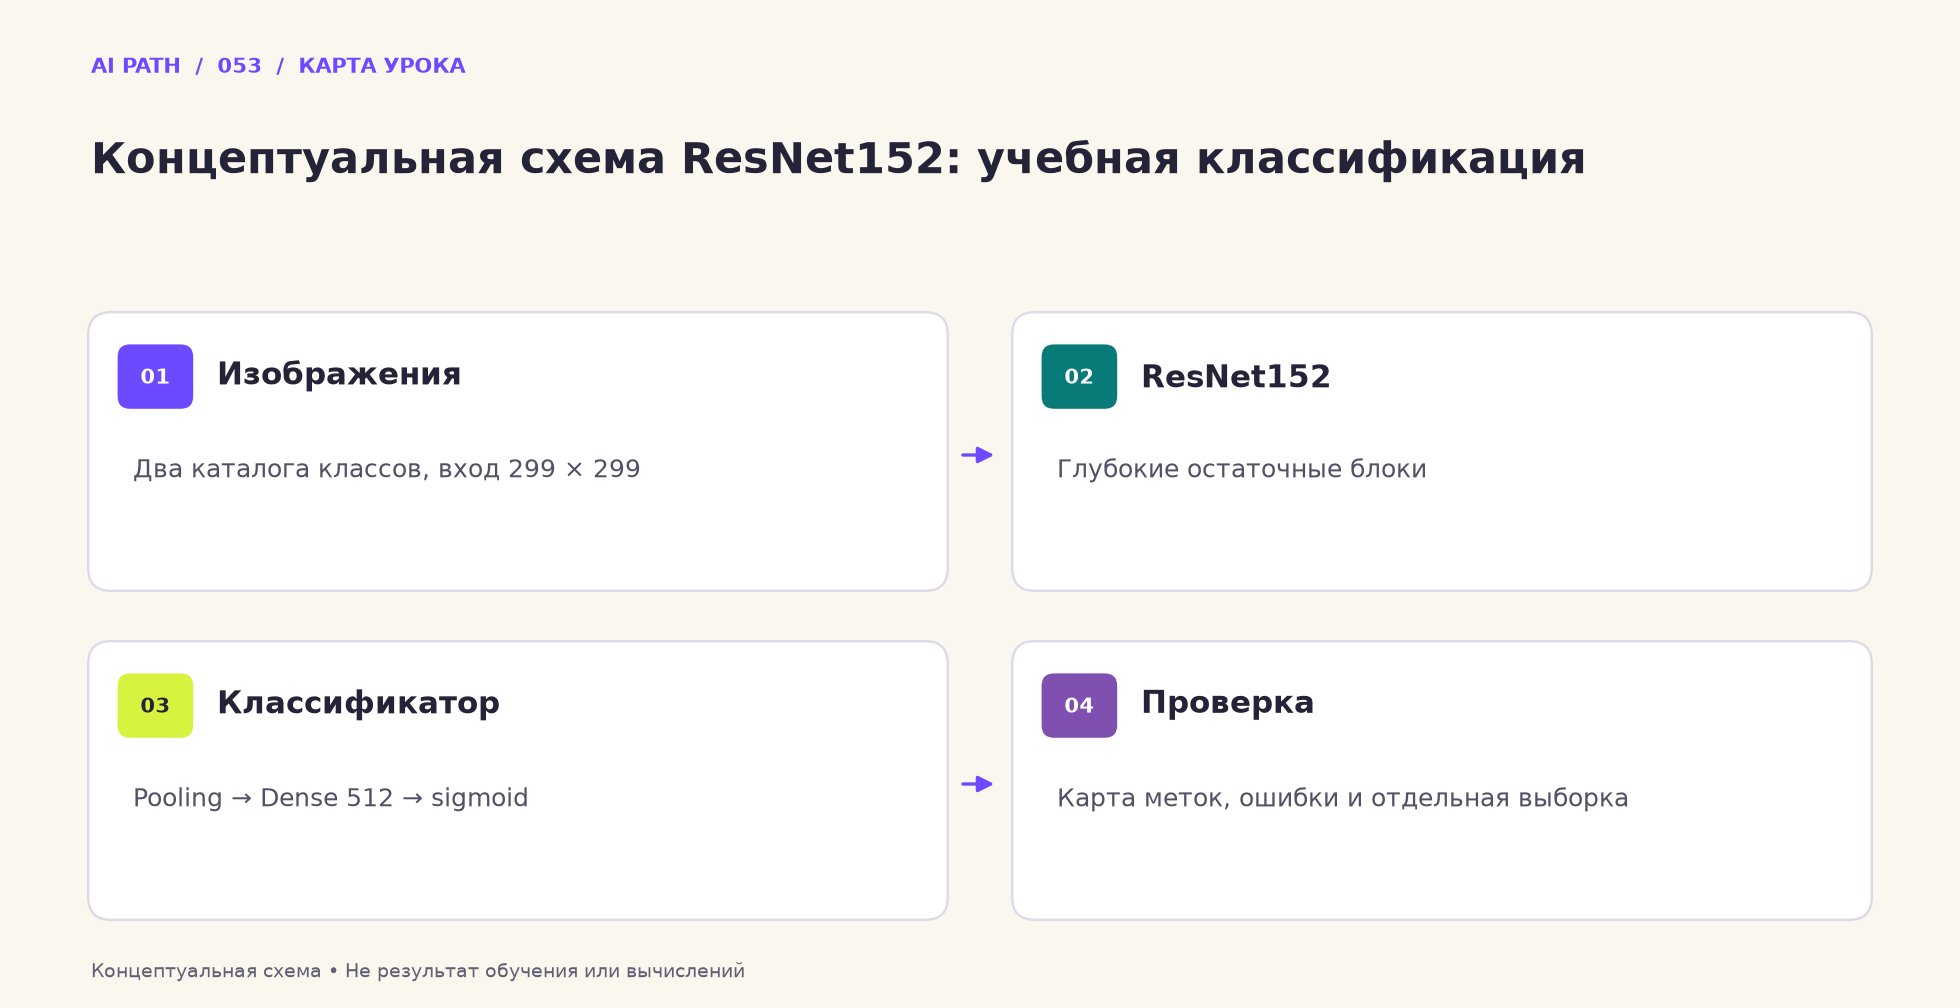

Схема показывает последовательность идей. Она не содержит результатов нового обучения или вычислений.

1. **Изображения** — Два каталога классов, вход 299 × 299
2. **ResNet152** — Глубокие остаточные блоки
3. **Классификатор** — Pooling → Dense 512 → sigmoid
4. **Проверка** — Карта меток, ошибки и отдельная выборка

<a href="https://colab.research.google.com/github/safal207/hello-world/blob/master/%22%D0%98%D1%81%D0%BF%D0%BE%D0%BB%D1%8C%D0%B7%D1%83%D0%B5%D0%BC_%D0%BC%D0%BE%D0%B4%D0%B5%D0%BB%D1%8C_ResNet_152_%D0%B4%D0%BB%D1%8F_%D1%80%D0%B0%D1%81%D0%BF%D0%BE%D0%B7%D0%BD%D0%B0%D0%B2%D0%B0%D0%BD%D0%B8%D1%8F_tuberculosis%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Автоматическое определение туберкулеза по флюорографии

**Норма**|**Патология**
---|---
![X-Ray Normal](https://www.dropbox.com/s/b5nk171zefpb55m/normal.png?dl=1) | ![X-Ray Tuberculesis](https://www.dropbox.com/s/1t2mko52jjignhu/tuberculosis.png?dl=1)

Для обучения использован открыты набор данных [Pulmonary Chest X-Ray Abnormalities](https://www.kaggle.com/kmader/pulmonary-chest-xray-abnormalities/home) на Kaggle. Исходные изображения были преобразованы к размеру 299х299 и распределены в каталоги по классам, как требует Keras. Ссылка на преобразованные изображения - https://www.dropbox.com/s/f64cvlhm0gp80v5/tuberculosis.zip?dl=1

Используется сеть Google InceptionV3, а также дополнение данных.

Чтобы запустить ноутбук, скопируйте его себе в Google Drive (меню File->Save a copy in Drive...).

При запуске желательно подключить GPU (меню Runtime -> Change runtime type -> Hardware Accelerator -> GPU), иначе сеть будет очень долго обучаться.

<a id="ai-053-section-01"></a>
## 01 · Архитектура и учебный контекст

Код использует ResNet152. Это исторический опыт классификации изображений из набора с метками Normal/Tuberculosis, а не инструмент постановки диагноза.

_Далее — исходные ячейки учебного материала._

In [2]:
from tensorflow.keras.applications.resnet import ResNet152


In [3]:
from tensorflow.keras.preprocessing import image
from tensorflow.keras.models import Model, load_model
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.layers import BatchNormalization, Activation
from tensorflow.keras.optimizers import Adam, RMSprop

from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline 

In [4]:
# Размер изображения
image_size = 299
# Размер мини-выборки
batch_size = 32

## Загружаем данные

<a id="ai-053-section-02"></a>
## 02 · Источник и разметка

Архив загружается извне. До обучения проверьте состав каталогов, происхождение изображений и отсутствие пересечений пациентов между выборками.

_Далее — исходные ячейки учебного материала._

In [5]:
!wget https://www.dropbox.com/s/f64cvlhm0gp80v5/tuberculosis.zip?dl=1 -O tuberculosis.zip

--2020-12-10 15:46:17--  https://www.dropbox.com/s/f64cvlhm0gp80v5/tuberculosis.zip?dl=1
Resolving www.dropbox.com (www.dropbox.com)... 162.125.80.18, 2620:100:6019:1::a27d:401
Connecting to www.dropbox.com (www.dropbox.com)|162.125.80.18|:443... connected.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: /s/dl/f64cvlhm0gp80v5/tuberculosis.zip [following]
--2020-12-10 15:46:18--  https://www.dropbox.com/s/dl/f64cvlhm0gp80v5/tuberculosis.zip
Reusing existing connection to www.dropbox.com:443.
HTTP request sent, awaiting response... 302 Found
Location: https://uc47dc737f65f784381a5eac9455.dl.dropboxusercontent.com/cd/0/get/BEyUNlbkHA2Mgg6SAvoKT21CMmEr2WAz9YMhBZEGHp8Gbklqf0N6UXTHmVSq-oJTMUiKbYqGuvZINWkxLpKlAoX9t-svft2G6s9qz-Lwxpv5Mg/file?dl=1# [following]
--2020-12-10 15:46:19--  https://uc47dc737f65f784381a5eac9455.dl.dropboxusercontent.com/cd/0/get/BEyUNlbkHA2Mgg6SAvoKT21CMmEr2WAz9YMhBZEGHp8Gbklqf0N6UXTHmVSq-oJTMUiKbYqGuvZINWkxLpKlAoX9t-svft2G6s9qz-Lwxpv5Mg/file?d

In [6]:
!ls 

sample_data  tuberculosis.zip


In [7]:
!unzip tuberculosis.zip

Archive:  tuberculosis.zip
   creating: base_dir/
   creating: base_dir/train_dir/
   creating: base_dir/train_dir/Normal/
  inflating: base_dir/train_dir/Normal/CHNCXR_0001_0.png  
  inflating: base_dir/train_dir/Normal/CHNCXR_0002_0.png  
  inflating: base_dir/train_dir/Normal/CHNCXR_0003_0.png  
  inflating: base_dir/train_dir/Normal/CHNCXR_0004_0.png  
  inflating: base_dir/train_dir/Normal/CHNCXR_0005_0.png  
  inflating: base_dir/train_dir/Normal/CHNCXR_0006_0.png  
  inflating: base_dir/train_dir/Normal/CHNCXR_0007_0.png  
  inflating: base_dir/train_dir/Normal/CHNCXR_0008_0.png  
  inflating: base_dir/train_dir/Normal/CHNCXR_0009_0.png  
  inflating: base_dir/train_dir/Normal/CHNCXR_0011_0.png  
  inflating: base_dir/train_dir/Normal/CHNCXR_0012_0.png  
  inflating: base_dir/train_dir/Normal/CHNCXR_0013_0.png  
  inflating: base_dir/train_dir/Normal/CHNCXR_0014_0.png  
  inflating: base_dir/train_dir/Normal/CHNCXR_0015_0.png  
  inflating: base_dir/train_dir/Normal/CHNCXR_0016_

In [8]:
!ls base_dir/val_dir

Normal	Tuberculosis


## Просматриваем примеры данных

Нормальное изображение

In [9]:
!ls base_dir/train_dir/Normal/

CHNCXR_0001_0.png  CHNCXR_0101_0.png  CHNCXR_0207_0.png  CHNCXR_0311_0.png
CHNCXR_0002_0.png  CHNCXR_0102_0.png  CHNCXR_0208_0.png  CHNCXR_0312_0.png
CHNCXR_0003_0.png  CHNCXR_0103_0.png  CHNCXR_0209_0.png  CHNCXR_0313_0.png
CHNCXR_0004_0.png  CHNCXR_0105_0.png  CHNCXR_0210_0.png  CHNCXR_0314_0.png
CHNCXR_0005_0.png  CHNCXR_0106_0.png  CHNCXR_0211_0.png  CHNCXR_0315_0.png
CHNCXR_0006_0.png  CHNCXR_0107_0.png  CHNCXR_0214_0.png  CHNCXR_0316_0.png
CHNCXR_0007_0.png  CHNCXR_0109_0.png  CHNCXR_0215_0.png  CHNCXR_0317_0.png
CHNCXR_0008_0.png  CHNCXR_0110_0.png  CHNCXR_0216_0.png  CHNCXR_0318_0.png
CHNCXR_0009_0.png  CHNCXR_0111_0.png  CHNCXR_0217_0.png  CHNCXR_0319_0.png
CHNCXR_0011_0.png  CHNCXR_0112_0.png  CHNCXR_0218_0.png  CHNCXR_0320_0.png
CHNCXR_0012_0.png  CHNCXR_0113_0.png  CHNCXR_0219_0.png  CHNCXR_0321_0.png
CHNCXR_0013_0.png  CHNCXR_0114_0.png  CHNCXR_0220_0.png  CHNCXR_0322_0.png
CHNCXR_0014_0.png  CHNCXR_0115_0.png  CHNCXR_0221_0.png  CHNCXR_0323_0.png
CHNCXR_0015_0.png  CHNCXR

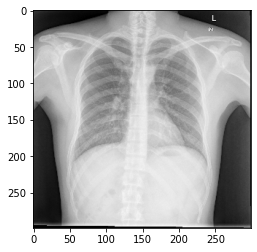

In [10]:
img_path = 'base_dir/train_dir/Normal/CHNCXR_0163_0.png'
img = image.load_img(img_path, target_size=(image_size, image_size))
plt.imshow(img)
plt.show()

Туберкулез

In [11]:
!ls base_dir/train_dir/Tuberculosis

CHNCXR_0328_1.png  CHNCXR_0428_1.png  CHNCXR_0531_1.png  CHNCXR_0622_1.png
CHNCXR_0329_1.png  CHNCXR_0429_1.png  CHNCXR_0532_1.png  CHNCXR_0623_1.png
CHNCXR_0330_1.png  CHNCXR_0432_1.png  CHNCXR_0533_1.png  CHNCXR_0624_1.png
CHNCXR_0331_1.png  CHNCXR_0435_1.png  CHNCXR_0535_1.png  CHNCXR_0625_1.png
CHNCXR_0332_1.png  CHNCXR_0436_1.png  CHNCXR_0536_1.png  CHNCXR_0626_1.png
CHNCXR_0333_1.png  CHNCXR_0437_1.png  CHNCXR_0537_1.png  CHNCXR_0628_1.png
CHNCXR_0334_1.png  CHNCXR_0441_1.png  CHNCXR_0538_1.png  CHNCXR_0630_1.png
CHNCXR_0335_1.png  CHNCXR_0442_1.png  CHNCXR_0539_1.png  CHNCXR_0631_1.png
CHNCXR_0336_1.png  CHNCXR_0443_1.png  CHNCXR_0540_1.png  CHNCXR_0632_1.png
CHNCXR_0338_1.png  CHNCXR_0444_1.png  CHNCXR_0541_1.png  CHNCXR_0633_1.png
CHNCXR_0339_1.png  CHNCXR_0445_1.png  CHNCXR_0542_1.png  CHNCXR_0634_1.png
CHNCXR_0340_1.png  CHNCXR_0446_1.png  CHNCXR_0543_1.png  CHNCXR_0635_1.png
CHNCXR_0342_1.png  CHNCXR_0447_1.png  CHNCXR_0544_1.png  CHNCXR_0637_1.png
CHNCXR_0343_1.png  CHNCXR

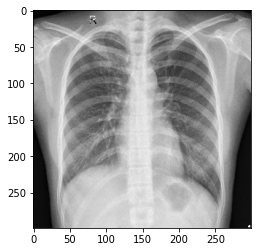

In [12]:
img_path = 'base_dir/train_dir/Tuberculosis/CHNCXR_0393_1.png'
img = image.load_img(img_path, target_size=(image_size, image_size))
plt.imshow(img)
plt.show()

## Создаем генераторы изображений

In [13]:
# Каталог с данными для обучения
train_dir = 'base_dir/train_dir'
test_dir = 'base_dir/val_dir'
# Размерность тензора на основе изображения для входных данных в нейронную сеть
# backend Tensorflow, channels_last
input_shape = (image_size, image_size, 3)

Генератор с дополнением данных (data augmentation)

<a id="ai-053-section-03"></a>
## 03 · Аугментации и входная шкала

Изображения становятся RGB-тензорами 299 × 299 и масштабируются через rescale=1./255. До повторения опыта сопоставьте такую обработку с требованиями выбранных ImageNet-весов ResNet152.

_Далее — исходные ячейки учебного материала._

In [14]:
train_datagen = ImageDataGenerator(rescale=1. / 255,
    rotation_range=10,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    fill_mode='nearest')

Проверяем генератор

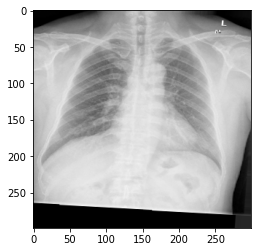

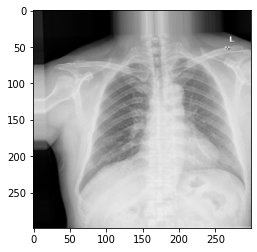

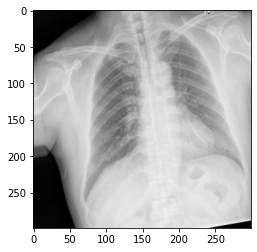

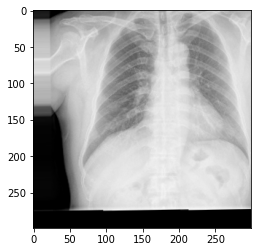

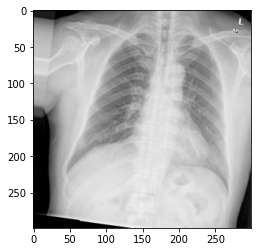

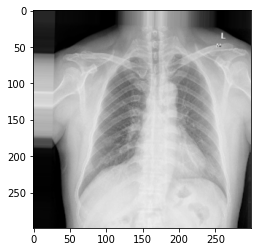

In [15]:
img_path = 'base_dir/train_dir/Normal/CHNCXR_0001_0.png'
img = image.load_img(img_path, target_size=(image_size, image_size))
x = image.img_to_array(img)
x = x.reshape((1,) + x.shape)
i = 0
for batch in train_datagen.flow(x, batch_size=1):
    plt.figure(i)
    imgplot = plt.imshow(image.array_to_img(batch[0]))
    i += 1
    if i % 6 == 0:
        break
plt.show()

Генератор для обучения

In [16]:
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(image_size, image_size),
    batch_size=batch_size,
    class_mode='binary')

Found 680 images belonging to 2 classes.


Генератор для тестирования без дополнения данных

In [17]:
test_datagen = ImageDataGenerator(rescale=1. / 255)

In [18]:
test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=(image_size, image_size),
    batch_size=batch_size,
    class_mode='binary')

Found 120 images belonging to 2 classes.


Номера классов в генераторах

In [19]:
train_generator.class_indices

{'Normal': 0, 'Tuberculosis': 1}

## Загружаем предварительно обученную нейронную сеть  ResNet152

<a id="ai-053-section-04"></a>
## 04 · Остаточная основа и новая голова

ResNet152 подключается без верхнего слоя; задача сведена к двум меткам через один sigmoid. Глубина сети сама по себе не подтверждает качество на этом наборе.

_Далее — исходные ячейки учебного материала._

In [20]:
pretrained_model = ResNet152(weights='imagenet', include_top=False)

234700800/234698864 [==============================] - 3s 0us/step


In [21]:
pretrained_model.summary()

Model: "resnet152"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_1 (InputLayer)            [(None, None, None,  0                                            
__________________________________________________________________________________________________
conv1_pad (ZeroPadding2D)       (None, None, None, 3 0           input_1[0][0]                    
__________________________________________________________________________________________________
conv1_conv (Conv2D)             (None, None, None, 6 9472        conv1_pad[0][0]                  
__________________________________________________________________________________________________
conv1_bn (BatchNormalization)   (None, None, None, 6 256         conv1_conv[0][0]                 
__________________________________________________________________________________________

"Замораживаем" веса предварительно обученной нейронной сети

In [22]:
pretrained_model.trainable = False

## Создаем составную нейронную сеть

In [23]:
x = pretrained_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(512)(x)
x = BatchNormalization()(x)
x = Activation('relu')(x)
x = Dropout(0.5)(x)
predictions = Dense(1, activation='sigmoid')(x)
model = Model(inputs=pretrained_model.input, outputs=predictions)

## Обучаем составную нейронную сеть на основе InceptionV3

In [24]:
model.compile(loss='binary_crossentropy',
              optimizer=RMSprop(lr=1e-4), 
              metrics=['accuracy'])

In [25]:
filepath="ResNet152_best.h5"
checkpoint = ModelCheckpoint(filepath, monitor='val_accuracy', verbose=1, 
                             save_best_only=True, mode='max')
learning_rate_reduction = ReduceLROnPlateau(monitor='val_accuracy', 
                                            patience=3, 
                                            verbose=1, 
                                            factor=0.5, 
                                            min_lr=0.00001)
callbacks_list = [checkpoint, learning_rate_reduction]

<a id="ai-053-section-05"></a>
## 05 · Первый этап и контрольная точка

Первый этап использует 35 эпох, 100 обучающих шагов и 5 проверочных. Зафиксируйте, какую долю данных действительно покрывает такой проход.

_Далее — исходные ячейки учебного материала._

In [27]:
steps_per_epoch = 100
history = model.fit_generator(
    train_generator,
    steps_per_epoch=steps_per_epoch,
    validation_data=test_generator,
    validation_steps=5,
    callbacks=callbacks_list,
    epochs=35,
    verbose=2)

Epoch 1/35

Epoch 00001: val_accuracy did not improve from 0.49167
 22/100 - 17s - loss: 0.6266 - accuracy: 0.6838 - val_loss: 0.7542 - val_accuracy: 0.4917


## Дообучение сверточных слоев resnet import ResNet152

Загружаем лучшие веса

<a id="ai-053-section-06"></a>
## 06 · Проверяем дообучаемые слои

После ResNet152_best.h5 код меняет trainable по индексу 249 и компилирует сеть заново. Второй этап задан на 25 эпох и 400 обучающих шагов.

_Далее — исходные ячейки учебного материала._

In [30]:
model.load_weights("ResNet152_best.h5")

Размораживаем два последних блока Inception

In [33]:
pretrained_model.trainable = False
for layer in model.layers[:249]:
   layer.trainable = False
for layer in model.layers[249:]:
   layer.trainable = True

Компилируем сеть с размороженными слоями

In [32]:
model.compile(loss='binary_crossentropy',
              optimizer=RMSprop(lr=1e-4), 
              metrics=['accuracy'])

In [34]:
filepath="ResNet152_best_fine_tuned.h5"
checkpoint = ModelCheckpoint(filepath, monitor='val_accuracy', verbose=1, save_best_only=True, mode='max')
callbacks_list = [checkpoint, learning_rate_reduction]

In [38]:
steps_per_epoch = 400
history = model.fit_generator(
    train_generator,
    steps_per_epoch=steps_per_epoch,
    validation_data=test_generator,
    validation_steps=5,
    callbacks=callbacks_list,
    epochs=25,
    verbose=2)

Epoch 1/25

Epoch 00001: val_accuracy did not improve from 0.57500
 22/400 - 22s - loss: 0.7729 - accuracy: 0.6544 - val_loss: 0.7112 - val_accuracy: 0.5083


## Тестируем модель

Загружаем обученные веса

<a id="ai-053-section-07"></a>
## 07 · Загружаем нужный артефакт

Загрузка ResNet152_best_fine_tuned.h5 должна соответствовать второму ModelCheckpoint; вместе с весами необходима та же карта классов.

_Далее — исходные ячейки учебного материала._

In [39]:
model = load_model("ResNet152_best_fine_tuned.h5")

Загружаем изображение

<a id="ai-053-section-08"></a>
## 08 · Один пример и границы вывода

Одиночный снимок преобразуется в тензор и сравнивается с порогом 0.5. Такой вывод не оценивает качество на популяции и не допускает клинической интерпретации.

_Далее — исходные ячейки учебного материала._

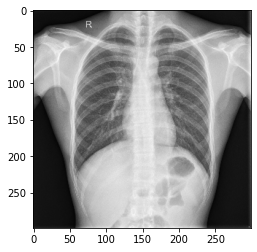

In [40]:
#img_path = 'base_dir/val_dir/Tuberculosis/CHNCXR_0337_1.png'
img_path = 'base_dir/val_dir/Normal/CHNCXR_0171_0.png'
#img_path = 'base_dir/val_dir/Tuberculosis/MCUCXR_0367_1.png'
img = image.load_img(img_path, target_size=(image_size, image_size))
plt.imshow(img)
plt.show()

Преобразуем изображение в массив для распознавания

In [41]:
x = image.img_to_array(img)
x /= 255
x = np.expand_dims(x, axis=0)

Запускаем распознавание

In [42]:
prediction = model.predict(x)

In [43]:
prediction

array([[0.47993663]], dtype=float32)

Метки классов: 

{'Normal': 0, 'Tuberculosis': 1}

In [44]:
if prediction[[0]] < 0.5:
    print('Normal')
else:
    print('Tuberculosis')

Normal


<a id="ai-053-practice"></a>
## Проверьте понимание

1. Как число шагов 100 или 400 связано с размером датасета и batch_size=32?
2. Какие остаточные блоки попадают после индекса 249 в установленной версии модели?
3. Почему один пример Normal после загрузки не проверяет полноту распознавания второго класса?

### Один самостоятельный эксперимент

Составьте карту обучаемых блоков до и после переключения trainable и сравните два режима при одинаковом количестве обработанных примеров.

**Критерий успеха:** Список слоёв и объём данных записаны явно; сравнение не смешивает изменение архитектуры с изменением числа проходов по данным.

<a id="ai-053-provenance"></a>
## Источники и ограничения

[Исходный ноутбук и его авторские материалы](https://github.com/safal207/students/blob/d848e04c8f8d6e3e8e42ce15fbd98c00612e0e17/medicina/%22%D0%98%D1%81%D0%BF%D0%BE%D0%BB%D1%8C%D0%B7%D1%83%D0%B5%D0%BC_%D0%BC%D0%BE%D0%B4%D0%B5%D0%BB%D1%8C_ResNet_152_%D0%B4%D0%BB%D1%8F_%D1%80%D0%B0%D1%81%D0%BF%D0%BE%D0%B7%D0%BD%D0%B0%D0%B2%D0%B0%D0%BD%D0%B8%D1%8F_tuberculosis%22.ipynb) · репозиторий `safal207/students`.

Исходные подписи, ссылки, авторство, код, изображения и аудио сохранены. Длинные текстовые выводы могут быть сокращены с указанием источника. Архивные результаты не пересчитывались.

### Перед новым запуском

- Архив и веса загружаются по сети; доступность, права использования, качество разметки и разделение по пациентам повторно не проверялись.
- Исходное введение упоминает Inception, но модель в коде — ResNet152.
- Подготовка пикселей и граница 249 не проверены на соответствие конкретной версии ResNet152; необходимо сверить их перед обучением.
- Глубокая сеть и второй этап с 400 шагами требуют оценки времени и памяти; старые lr/fit_generator могут потребовать адаптации.
- Валидация используется для выбора контрольной точки и не является независимым итоговым тестом; заданные steps/validation_steps нужно сверить с реальным числом пакетов.
- Обучение и медицинская проверка не выполнялись. Старые проценты и одиночные ответы сохранены как история опыта, не как доказательство точности или пригодности для диагностики.

**Иллюстрации:** обложка направления AI PATH; карта урока подготовлена по содержимому исходных ячеек.